# Lecture 7: The Bloch Sphere and Quantum Gates

[Course contents](../00_course_contents.md) | [← Previous lecture](./06_density_matrices_and_entanglement.ipynb) | [Next lecture →](./08_quantum_circuits_with_qiskit.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Convert between state-vector, density-matrix, and Bloch-vector descriptions of one qubit.
- Distinguish global phase, relative phase, and physical rotations.
- Interpret common one- and two-qubit gates as unitary transformations.
- Embed irreversible Boolean functions in reversible circuits.
- Identify local, entangling, Clifford, and universal gate resources.

## Core ideas

- **The Bloch sphere represents one-qubit density operators; pure states lie on the surface and mixed states inside.**
- **One-qubit gates are rotations up to global phase.** Circuit order and matrix multiplication order must not be confused.
- **Entangling gates supply the nonlocal resource.** Arbitrary one-qubit control plus a suitable entangling gate is universal.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from sympy.physics.quantum import *
from sympy.physics.quantum.qubit import Qubit
from sympy.physics.quantum.dagger import Dagger
from sympy.physics.quantum.qapply import qapply
from sympy.physics.quantum.represent import represent
from sympy.physics.quantum import pauli
from IPython.core.interactiveshell import InteractiveShell
from qiskit.visualization import plot_bloch_vector
from qutip import Bloch
from sympy.physics.quantum.gate import *
from sympy.physics.quantum.circuitplot import *
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
import math
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy
import scipy as sp

## Recorded lectures

### Bloch-sphere review


[Watch "Bloch sphere" on YouTube](https://www.youtube.com/watch?v=fq4eAcsWcEU).


### Quantum gates and circuits


[Watch "Quantum gates and circuits" on YouTube](https://www.youtube.com/watch?v=yk1OmY7axok).


In [2]:
# Import general libraries

%matplotlib inline

In [3]:
#Activate multiple output
InteractiveShell.ast_node_interactivity = "all"

## Pure qubit states and the Bloch sphere

The Bloch sphere represents physical pure states of one qubit as points on the unit sphere. State vectors that differ only by a global phase represent the same point. Density operators extend the picture to the entire Bloch ball: mixed states lie inside the sphere and the maximally mixed state lies at its center.


A normalized qubit state is

$$\lvert\psi\rangle=c_0\lvert0\rangle+c_1\lvert1\rangle,
\qquad \lvert c_0\rvert^2+\lvert c_1\rvert^2=1.$$

Multiplying by a global phase does not change any probability or expectation value. Except at $c_0=0$, choose that phase so $c_0$ is real and nonnegative, then write

$$\boxed{\lvert\psi(\theta,\phi)\rangle=
\cos\frac{\theta}{2}\lvert0\rangle+
e^{i\phi}\sin\frac{\theta}{2}\lvert1\rangle},$$

with $0\le\theta\le\pi$ and $0\le\phi<2\pi$. The corresponding Bloch vector is

$$\mathbf r=(\sin\theta\cos\phi,\sin\theta\sin\phi,\cos\theta).$$

At the poles, $\phi$ is irrelevant. The half-angle is a consequence of the spinor representation; it is not a normalization trick.


### The Bloch ball and measurable coordinates

Every one-qubit density operator has the unique form

$$\boxed{\rho=\frac12\left(I+r_xX+r_yY+r_zZ\right)},$$

where

$$r_x=\operatorname{Tr}(\rho X),\qquad
r_y=\operatorname{Tr}(\rho Y),\qquad
r_z=\operatorname{Tr}(\rho Z).$$

Positivity is equivalent to $\lVert\mathbf r\rVert\le1$, and the eigenvalues are

$$\lambda_\pm=\frac{1\pm\lVert\mathbf r\rVert}{2}.$$

Pure states have $\lVert\mathbf r\rVert=1$; mixed states have $\lVert\mathbf r\rVert<1$. The purity is

$$\operatorname{Tr}(\rho^2)=\frac{1+\lVert\mathbf r\rVert^2}{2}.$$

A projective measurement along unit direction $\mathbf n$ has effects $P_\pm=(I\pm\mathbf n\cdot\boldsymbol\sigma)/2$ and probabilities

$$p(\pm)=\frac{1\pm\mathbf r\cdot\mathbf n}{2}.$$

This gives an engineering route to single-qubit tomography: estimate the three Pauli expectations from repeated measurements, then enforce physicality when finite-shot estimates fall slightly outside the Bloch ball.


### Bloch-sphere visualization with Qiskit and QuTiP


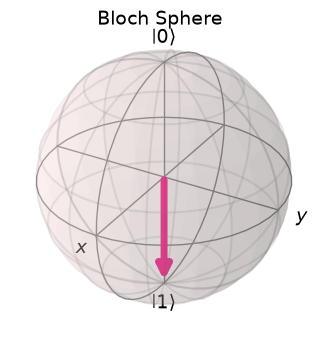

Fig.2.1: Bloch Sphere


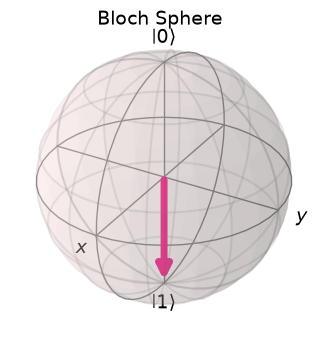

In [4]:
# Qiskit realisation

  
plot_bloch_vector([1, np.pi, 1], figsize=(3,3), coord_type='spherical', title="Bloch Sphere", font_size=(14))

print('Fig.2.1: Bloch Sphere')

*The Qiskit and QuTiP renderings both place the Bloch vector at the south pole, corresponding to the computational-basis state $|1\rangle$ under the stated axis convention.*


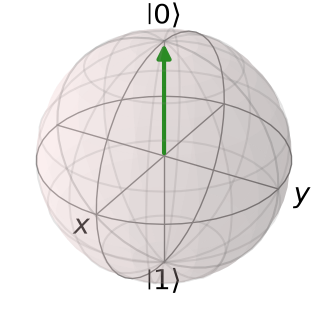

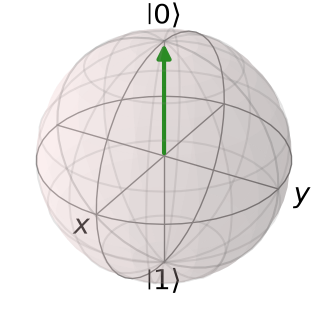

In [5]:
# QuTiP realization

b = Bloch()
b.figsize = [3, 3]
b.add_vectors([0, 0, 1])  # |0> is the north pole.
b.show()

*The second renderer reproduces the same south-pole Bloch vector, showing that the physical state is independent of the plotting library.*


### Computational-basis states

Using Euler's formula,

$$\lvert\psi\rangle=\cos\frac{\theta}{2}\lvert0\rangle+
(\cos\phi+i\sin\phi)\sin\frac{\theta}{2}\lvert1\rangle.$$

The state $\lvert0\rangle$ is the north pole $\theta=0$, and $\lvert1\rangle$ is the south pole $\theta=\pi$. The azimuth $\phi$ is undefined at either pole. These orthogonal states are antipodal and give deterministic, opposite outcomes for a $Z$-basis measurement.


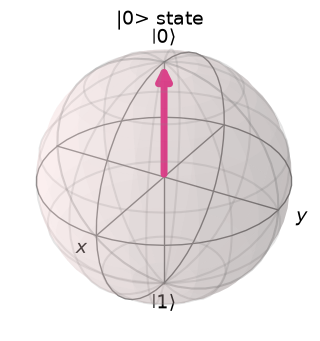

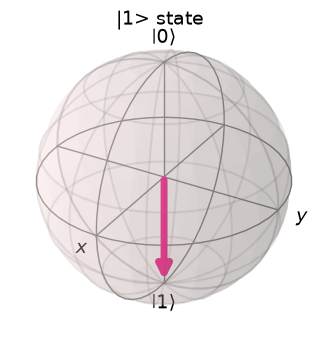

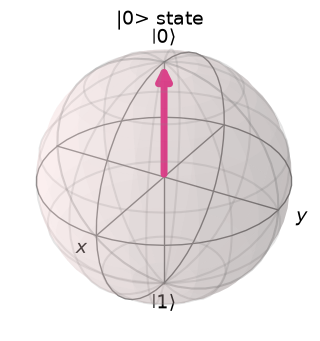

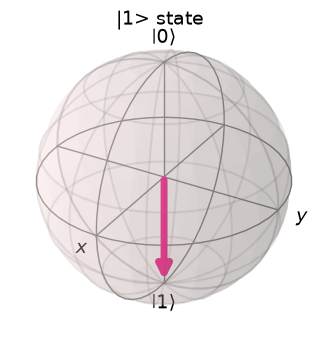

In [6]:
plot_bloch_vector([1, 0, 0], figsize=(3,3), coord_type='spherical', title="|0> state", font_size=(14))
plot_bloch_vector([1, np.pi, 0], figsize=(3,3), coord_type='spherical', title="|1> state", font_size=(14))

*The two plots place $|0\rangle$ at the north pole and $|1\rangle$ at the south pole; they are antipodal eigenstates of $Z$.*


### $X$-basis states

$$\lvert+\rangle=\frac{\lvert0\rangle+\lvert1\rangle}{\sqrt2}
\quad\longleftrightarrow\quad(\theta,\phi)=\left(\frac\pi2,0\right),$$

$$\lvert-\rangle=\frac{\lvert0\rangle-\lvert1\rangle}{\sqrt2}
\quad\longleftrightarrow\quad(\theta,\phi)=\left(\frac\pi2,\pi\right).$$

They have equal $Z$-basis probabilities but opposite $X$-measurement outcomes. "Superposition" is basis dependent: $\lvert+\rangle$ is a superposition in the $Z$ basis and an eigenstate in the $X$ basis.


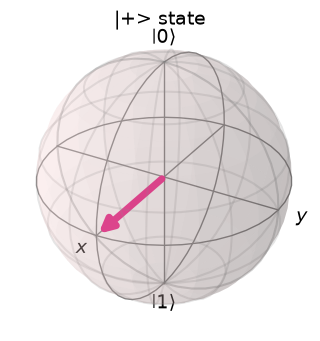

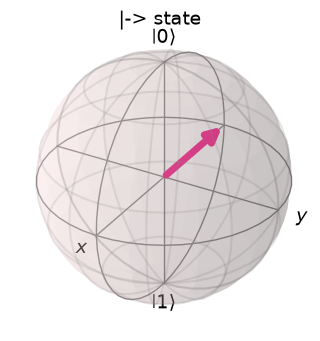

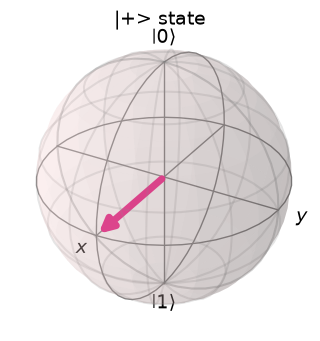

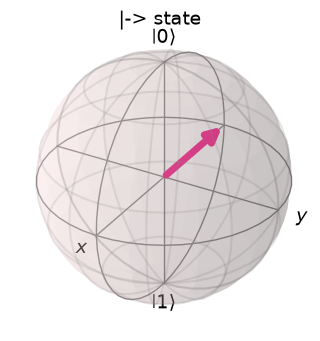

In [7]:
plot_bloch_vector([1, np.pi/2, 0], figsize=(3,3), coord_type='spherical', title="|+> state", font_size=(14))
plot_bloch_vector([1, np.pi/2, np.pi], figsize=(3,3), coord_type='spherical', title="|-> state", font_size=(14))

*The states $|+\rangle$ and $|-\rangle$ appear at opposite points on the equator along the $x$ axis, reflecting their $X$ eigenvalues $+1$ and $-1$.*


### $Y$-basis states

$$\lvert+i\rangle=\frac{\lvert0\rangle+i\lvert1\rangle}{\sqrt2}
\quad\longleftrightarrow\quad(\theta,\phi)=\left(\frac\pi2,\frac\pi2\right),$$

$$\lvert-i\rangle=\frac{\lvert0\rangle-i\lvert1\rangle}{\sqrt2}
\quad\longleftrightarrow\quad(\theta,\phi)=\left(\frac\pi2,\frac{3\pi}{2}\right).$$

They lie on the $y$ axis and are eigenstates of $Y$ with eigenvalues $+1$ and $-1$, respectively.


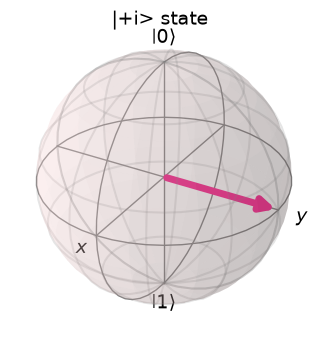

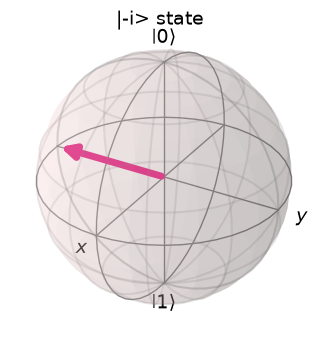

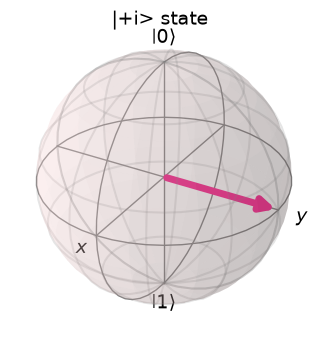

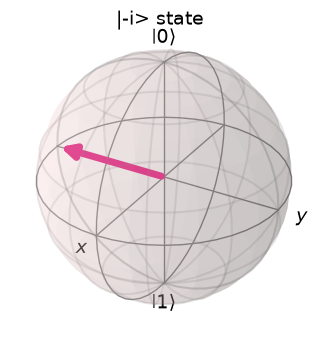

In [8]:
plot_bloch_vector([1, np.pi/2, np.pi/2], figsize=(3,3), coord_type='spherical', title="|+i> state", font_size=(14))
plot_bloch_vector([1, np.pi/2, 3*np.pi/2], figsize=(3,3), coord_type='spherical', title="|-i> state", font_size=(14))

*The states $|+i\rangle$ and $|-i\rangle$ lie at opposite equatorial points along the $y$ axis, reflecting their $Y$ eigenvalues $+1$ and $-1$.*


### Global phase, relative phase, and the SU(2) double cover

The states $\lvert\psi\rangle$ and $e^{i\gamma}\lvert\psi\rangle$ are physically equivalent for an isolated branch, but changing the relative phase between basis amplitudes changes the Bloch azimuth and can change later interference.

A rotation by angle $\alpha$ about unit axis $\mathbf n$ is

$$R_{\mathbf n}(\alpha)=e^{-i\alpha\mathbf n\cdot\boldsymbol\sigma/2}
=\cos\frac\alpha2 I-i\sin\frac\alpha2\mathbf n\cdot\boldsymbol\sigma.$$

It rotates the Bloch vector by $\alpha$. A $2\pi$ rotation gives $-I$, which differs from $I$ only by global phase on a standalone state, while a $4\pi$ rotation returns $I$. This two-to-one mapping from $SU(2)$ to spatial rotations is the precise sense in which spinor half-angles appear.


## Quantum gates and circuit abstractions


### Classical logic, information loss, and reversible embeddings

Classical circuits commonly use NOT, AND, OR, and XOR operations.

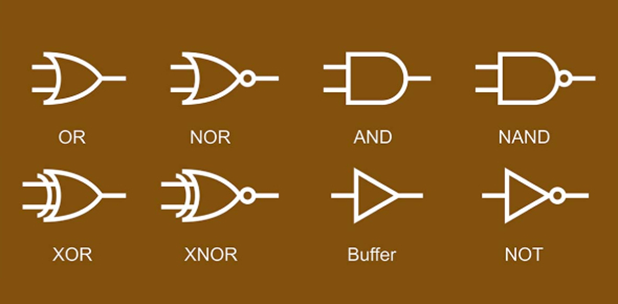

NOT is reversible: $0\leftrightarrow1$. The two-input, one-output XOR function $f(a,b)=a\oplus b$ is not reversible because four inputs map to two outputs. Quantum gates must instead implement a bijection on computational-basis states within a coherent unitary block.

XOR has the reversible embedding

$$\boxed{(a,b)\longmapsto(a,a\oplus b)},$$

which is exactly CNOT. Similarly, the Toffoli transformation

$$\lvert a,b,c\rangle\longmapsto\lvert a,b,c\oplus ab\rangle$$

reversibly embeds AND while preserving its inputs. Practical reversible designs use ancillas for intermediate values and *uncompute* temporary garbage so it does not remain entangled with the desired result.


### Example: an adder

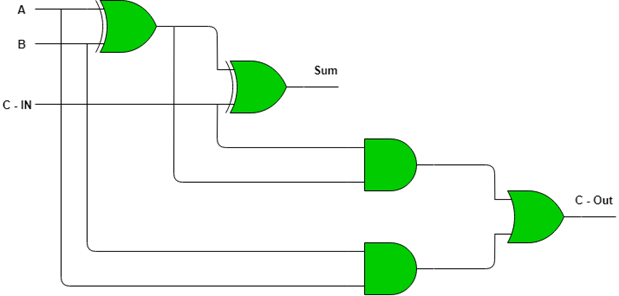

A classical adder can discard carry history and overwrite inputs. A coherent quantum adder must retain enough information to be invertible, typically by preserving input registers or writing the sum into a separate register. Ancilla count, gate count, circuit depth, and connectivity then become engineering resources.


### Quantum circuit model

An ideal coherent gate is unitary,

$$U^\dagger U=UU^\dagger=I,$$

so it is norm preserving and reversible. A circuit composes gates; if $U_1$ acts first and $U_2$ second, the state becomes $U_2U_1\lvert\psi\rangle$. Matrix multiplication therefore runs right to left even though diagrams are usually read left to right.

Measurement, reset, classical control, and noise are not unitary operations on the modeled qubits alone; they are represented by instruments or quantum channels. Thus unitarity applies to closed coherent blocks, not to every operation in an experimental program.

**Schematic quantum circuit** (source: [DOI 10.1109/TQE.2021.3053921](https://doi.org/10.1109/TQE.2021.3053921)):

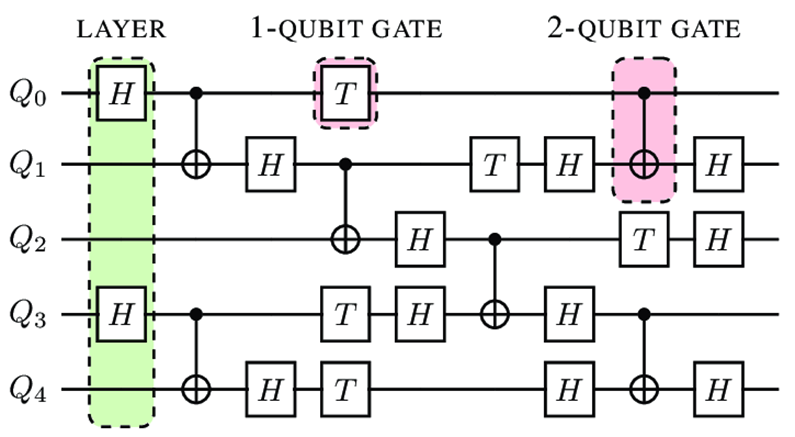


### Logical diagrams versus hardware execution

A circuit diagram is an abstraction of qubits, dependencies, and operations; it is neither a chip floorplan nor a complete timing diagram. Physical qubits occupy hardware locations and interact through a coupling graph. Calibrated control waveforms implement native instructions, and different instructions have different durations and error mechanisms.

Compilation maps logical qubits to physical qubits, decomposes operations into the target instruction set, and inserts routing operations when required by connectivity. A scheduler may overlap independent operations while respecting resource conflicts and dependencies. Consequently, circuit depth, scheduled duration, two-qubit-gate count, and estimated error are different metrics.

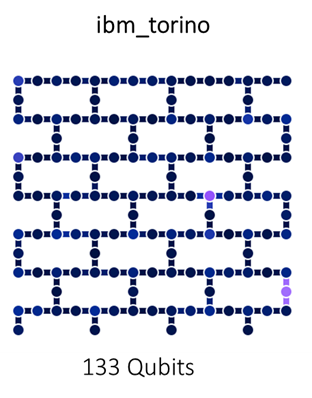


## Single-qubit gates

Single-qubit gates are $2\times2$ unitaries. Ignoring global phase, every such gate is a rotation of the Bloch sphere.

### X gate

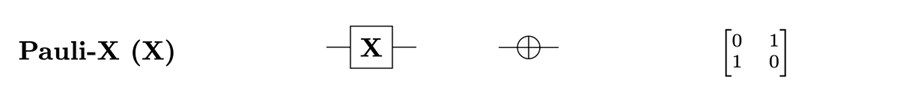

$$X=\begin{bmatrix}0&1\\1&0\end{bmatrix},\qquad
X\lvert0\rangle=\lvert1\rangle,\qquad
X\lvert1\rangle=\lvert0\rangle.$$

For $\lvert\psi\rangle=\alpha\lvert0\rangle+\beta\lvert1\rangle$,

$$X\lvert\psi\rangle=\beta\lvert0\rangle+\alpha\lvert1\rangle.$$

Since $R_x(\pi)=-iX$, the $X$ gate acts as a $\pi$ Bloch rotation about $x$, up to global phase.


### Arbitrary single-qubit gates and Euler angles

Up to global phase, any one-qubit unitary can be decomposed as

$$U=R_z(\phi)R_y(\theta)R_z(\lambda).$$

Qiskit's conventional parameterized $U(\theta,\phi,\lambda)$ matrix is

$$U(\theta,\phi,\lambda)=
\begin{bmatrix}
\cos(\theta/2)&-e^{i\lambda}\sin(\theta/2)\\
e^{i\phi}\sin(\theta/2)&e^{i(\phi+\lambda)}\cos(\theta/2)
\end{bmatrix}.$$

This decomposition matters in control engineering: a compiler can express a requested logical gate through a small calibrated native family rather than calibrating every possible unitary separately.

Official reference: IBM Quantum, [UGate API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.UGate).


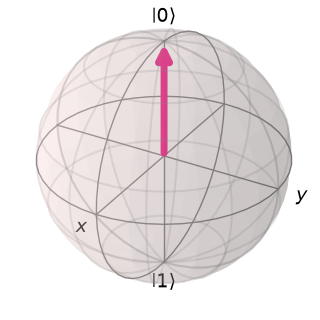

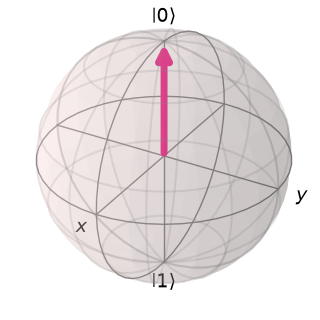

In [9]:
plot_bloch_vector([1, 0, 0], figsize=(3,3), coord_type='spherical', font_size=(14))

*The north-pole vector represents the input $|0\rangle$ used to connect state preparation with the following one-qubit gate examples.*


In [10]:
X(0)*Qubit('0')
qapply(X(0)*Qubit('0'))
qapply(X(0)*Qubit('001'))

X(0)*|0>

|1>

|000>

In [11]:
represent(qapply(X(0)*Qubit('0')))

Matrix([
[0],
[1]])

### Browser-based exploration with Quirk

[Quirk](https://algassert.com/quirk) provides an interactive circuit and state visualizer.

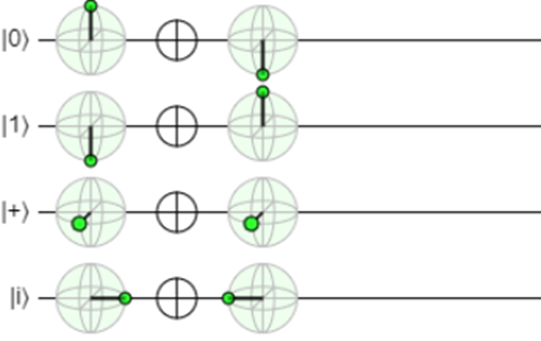

Its practical circuit width depends on browser resources and on the simulated structure; avoid presenting a fixed qubit limit. Generic statevector simulation requires memory proportional to $2^n$.


In [12]:
n = 16
print(f"A generic {n}-qubit statevector has {2**n:,} complex amplitudes.")

A generic 16-qubit statevector has 65,536 complex amplitudes.


### Y gate

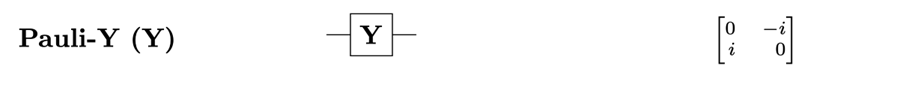

$$Y=\begin{bmatrix}0&-i\\i&0\end{bmatrix},\qquad
Y\lvert0\rangle=i\lvert1\rangle,\qquad
Y\lvert1\rangle=-i\lvert0\rangle.$$

Therefore,

$$Y(\alpha\lvert0\rangle+\beta\lvert1\rangle)
=-i\beta\lvert0\rangle+i\alpha\lvert1\rangle.$$

Since $R_y(\pi)=-iY$, the gate acts as a $\pi$ rotation about $y$, up to global phase.


In [13]:
qapply(Y(0)*Qubit('0'))
qapply(Y(0)*Qubit('1'))

I*|1>

-I*|0>

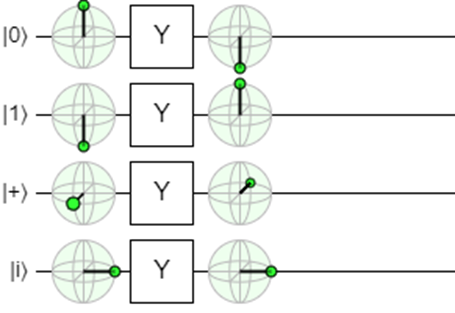

*The four rows show how the Pauli-$Y$ gate maps representative computational- and equatorial-basis states to new points on the Bloch sphere, including the relative phases carried by $Y$.*


In [14]:
ps = Qubit('0')+Qubit('1')
ms = Qubit('0')-Qubit('1')

qapply(Y(0)*ps)
qapply(Y(0)*ms)

-I*|0> + I*|1>

I*|0> + I*|1>

### Z gate

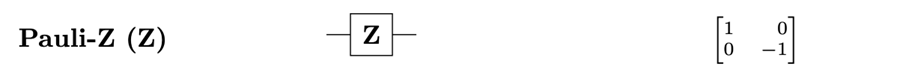

$$Z=\begin{bmatrix}1&0\\0&-1\end{bmatrix},\qquad
Z\lvert0\rangle=\lvert0\rangle,\qquad
Z\lvert1\rangle=-\lvert1\rangle.$$

Thus

$$Z(\alpha\lvert0\rangle+\beta\lvert1\rangle)
=\alpha\lvert0\rangle-\beta\lvert1\rangle.$$

Since $R_z(\pi)=-iZ$, the gate acts as a $\pi$ rotation about $z$, up to global phase. Its effect is invisible in an immediate $Z$-basis measurement but can be converted into a population difference by later interference.


In [15]:
qapply(Z(0)*Qubit('0'))
qapply(Z(0)*Qubit('1'))

|0>

-|1>

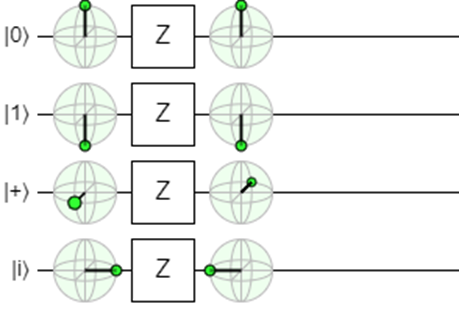

*The Bloch-sphere rows show that $Z$ leaves the poles fixed up to phase and exchanges the $X$-basis directions by changing their relative phase.*


### Hadamard gate

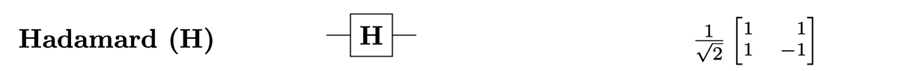

$$H=\frac1{\sqrt2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}
=\frac{X+Z}{\sqrt2}.$$

Its action is

$$H\lvert0\rangle=\lvert+\rangle,\qquad
H\lvert1\rangle=\lvert-\rangle,$$

$$H(\alpha\lvert0\rangle+\beta\lvert1\rangle)
=\frac{(\alpha+\beta)\lvert0\rangle+(\alpha-\beta)\lvert1\rangle}{\sqrt2}.$$

On the Bloch sphere, $H$ is a $\pi$ rotation about axis $(\hat x+\hat z)/\sqrt2$, up to global phase. It swaps the $X$ and $Z$ axes: $HXH=Z$ and $HZH=X$. It creates equal $Z$-basis amplitudes from $\lvert0\rangle$, but it does not create a superposition from every input; for example $H\lvert+\rangle=\lvert0\rangle$.


In [16]:
qapply(H(0)*Qubit('0'))
qapply(H(0)*Qubit('1'))

sqrt(2)*|0>/2 + sqrt(2)*|1>/2

sqrt(2)*|0>/2 - sqrt(2)*|1>/2

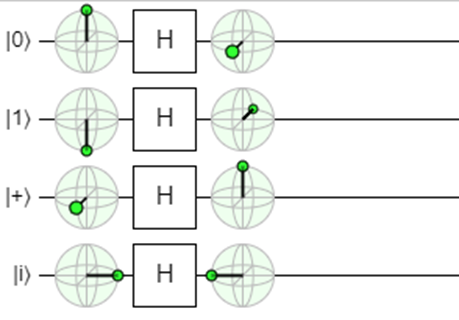

*The Hadamard rows visualize the exchange between the computational and $X$ bases: $|0\rangle\leftrightarrow|+\rangle$ and $|1\rangle\leftrightarrow|-\rangle$ up to the displayed conventions.*


### Phase gate

$$P(\phi)=\begin{bmatrix}1&0\\0&e^{i\phi}\end{bmatrix},$$

so

$$P(\phi)\lvert0\rangle=\lvert0\rangle,\qquad
P(\phi)\lvert1\rangle=e^{i\phi}\lvert1\rangle.$$

For a general state,

$$P(\phi)(\alpha\lvert0\rangle+\beta\lvert1\rangle)
=\alpha\lvert0\rangle+e^{i\phi}\beta\lvert1\rangle.$$

Because $P(\phi)=e^{i\phi/2}R_z(\phi)$, it is a $z$-axis rotation up to global phase.


### S gate

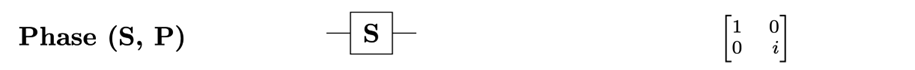

$$S=P\!\left(\frac\pi2\right)=\begin{bmatrix}1&0\\0&i\end{bmatrix},
\qquad S^2=Z.$$

It maps $\lvert0\rangle\mapsto\lvert0\rangle$ and $\lvert1\rangle\mapsto i\lvert1\rangle$. The $S$ gate is a Clifford gate because it conjugates Pauli operators to Pauli operators.


In [17]:
qapply(PhaseGate(0)*Qubit('0'))
qapply(PhaseGate(0)*Qubit('1'))

|0>

I*|1>

### T gate

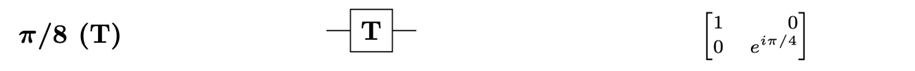

$$T=P\!\left(\frac\pi4\right)=
\begin{bmatrix}1&0\\0&e^{i\pi/4}\end{bmatrix},
\qquad T^2=S.$$

It maps $\lvert0\rangle\mapsto\lvert0\rangle$ and $\lvert1\rangle\mapsto e^{i\pi/4}\lvert1\rangle$. Unlike $S$, $T$ is non-Clifford; adding it to Clifford operations enables universal approximation of unitaries.


In [18]:
qapply(TGate(0)*Qubit('0'))
qapply(TGate(0)*Qubit('1'))

|0>

exp(I*pi/4)*|1>

## Two-qubit gates

Two-qubit gates can couple subsystems, but a particular gate does not entangle every input. For example, CNOT leaves $\lvert00\rangle$ unchanged and maps $\lvert+0\rangle$ to an entangled Bell state. Two-qubit operations are often slower and noisier than single-qubit operations, so their count and placement are important compilation metrics.


### CNOT gate

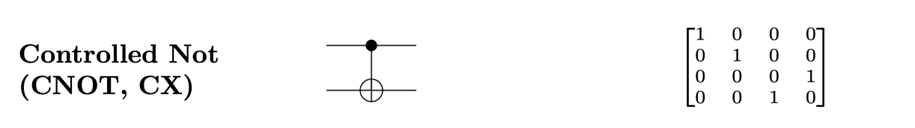

Using ordered basis $\lvert00\rangle,\lvert01\rangle,\lvert10\rangle,\lvert11\rangle$, with the first qubit as control and the second as target,

$$\operatorname{CNOT}=\begin{bmatrix}
1&0&0&0\\
0&1&0&0\\
0&0&0&1\\
0&0&1&0
\end{bmatrix}.$$

Its Boolean action is

$$\lvert a,b\rangle\longmapsto\lvert a,a\oplus b\rangle.$$

Therefore

$$\lvert00\rangle\mapsto\lvert00\rangle,\quad
\lvert01\rangle\mapsto\lvert01\rangle,\quad
\lvert10\rangle\mapsto\lvert11\rangle,\quad
\lvert11\rangle\mapsto\lvert10\rangle.$$

Software may label tensor factors and wire indices differently, so the basis order and control-target order must accompany any matrix.


In [19]:
qapply(CNotGate(1,0)*Qubit('00'))
qapply(CNotGate(1,0)*Qubit('01'))

qapply(CNOT(1,0)*Qubit('10'))
qapply(CNOT(1,0)*Qubit('11'))

|00>

|01>

|11>

|10>

### Controlled-Z gate

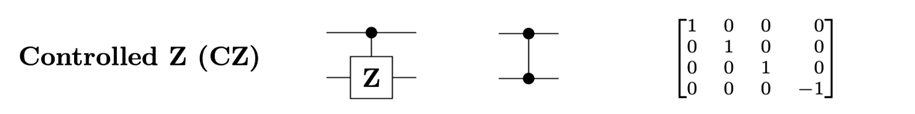

$$\operatorname{CZ}=\operatorname{diag}(1,1,1,-1).$$

It multiplies the joint $\lvert11\rangle$ component by $-1$ and leaves the other computational-basis states unchanged. CZ is symmetric under exchanging its two qubits, so speaking of a unique "target" is unnecessary. It is locally equivalent to CNOT:

$$\operatorname{CZ}=(I\otimes H)\operatorname{CNOT}(I\otimes H),$$

for the CNOT convention above.


### SWAP gate

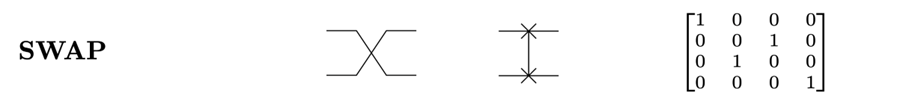

$$\operatorname{SWAP}=\begin{bmatrix}
1&0&0&0\\
0&0&1&0\\
0&1&0&0\\
0&0&0&1
\end{bmatrix},\qquad
\operatorname{SWAP}\lvert a,b\rangle=\lvert b,a\rangle.$$

SWAP maps product states to product states and does not itself generate entanglement, but it can move logical states across limited-connectivity hardware. Three CNOTs implement a SWAP when CNOT is native.


### Local gates, entangling gates, and universality

A local unitary $U_A\otimes U_B$ cannot change a pure state's Schmidt coefficients and therefore cannot create or destroy bipartite entanglement. An entangling two-qubit gate is one that produces an entangled state from at least one product input.

Arbitrary one-qubit unitaries together with any suitable entangling two-qubit gate form a universal set. A common discrete set is Clifford+T: the Clifford gates $H$, $S$, and CNOT efficiently transform Pauli operators, while the non-Clifford $T$ gate supplies universality for approximation. "Universal" means arbitrary accuracy with increasing circuit length, not exact synthesis of every unitary with a fixed finite circuit.

Primary reference: A. Barenco et al., ["Elementary gates for quantum computation"](https://doi.org/10.1103/PhysRevA.52.3457), *Physical Review A* 52, 3457-3467 (1995).


In [20]:
qapply(SwapGate(1,0)*Qubit('00'))
qapply(SwapGate(1,0)*Qubit('01'))

qapply(SWAP(1,0)*Qubit('10'))
qapply(SWAP(1,0)*Qubit('11'))

|00>

|10>

|01>

|11>

### Circuit plots with SymPy


CNOT(3,4)*Z(2)*Y(1)*X(0)*|00000>

I*|00011>

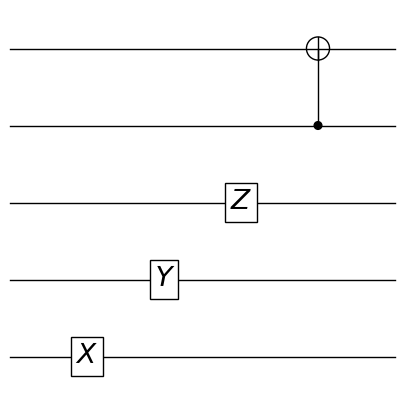

In [21]:
circuit_plot(CNOT(3,4)*Z(2)*Y(1)*X(0), nqubits = 5)

CNOT(3,4)*Z(2)*Y(1)*X(0)*Qubit('00000')
qapply(CNOT(3,4)*Z(2)*Y(1)*X(0)*Qubit('00000'))
#represent(qapply(CNOT(3,4)*Z(2)*Y(1)*X(0)*Qubit('00000')))

*The five-wire SymPy circuit combines independent $X$, $Y$, and $Z$ gates with a CNOT; the plotted wire order follows SymPy's qubit-index convention.*


### Bell-state circuit


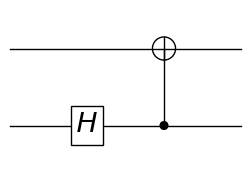

In [22]:
circuit_plot(CNOT(0,1)*H(0), nqubits = 2)

*The two-wire SymPy circuit applies a Hadamard followed by CNOT to prepare a Bell state; algebraic time order is right to left even though the circuit is read left to right.*


In [23]:
initstate = Qubit('00')

finstate = qapply(CNOT(0,1)*H(0)*initstate); finstate

sqrt(2)*|00>/2 + sqrt(2)*|11>/2

Starting from $\lvert00\rangle$, apply $H$ to the control and then CNOT:

$$\lvert00\rangle\xrightarrow{H\otimes I}
\frac{\lvert00\rangle+\lvert10\rangle}{\sqrt2}
\xrightarrow{\operatorname{CNOT}}
\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt2}
=\lvert\Phi^+\rangle.$$

The intermediate ket assumes the first qubit is the control. A library with a different printed tensor-factor convention may display the same physical circuit with bit labels reversed.

#### Bell-state analysis by circuit inversion

A Bell-state analyzer reverses the preparation circuit. In Qiskit's convention, prepare with $H(q_0)$ followed by $\operatorname{CNOT}(q_0,q_1)$, and analyze with the inverse order: $\operatorname{CNOT}(q_0,q_1)$ followed by $H(q_0)$. Because both gates are self-inverse, no additional gate definitions are needed.

With computational strings written as $\lvert q_1q_0\rangle$, the analyzer maps

$$
\lvert\Phi^+\rangle\mapsto\lvert00\rangle,\qquad
\lvert\Phi^-\rangle\mapsto\lvert01\rangle,\qquad
\lvert\Psi^+\rangle\mapsto\lvert10\rangle,\qquad
\lvert\Psi^-\rangle\mapsto\lvert11\rangle,
$$

up to an irrelevant global phase. Measurement after this inverse circuit therefore identifies the four Bell states in the ideal model. Experimental discrimination additionally depends on gate, readout, and assignment errors.


### Verifying entanglement rather than naming it

The output above is not a product state. Its reduced density operators are both $I/2$, its Schmidt coefficients are $1/\sqrt2,1/\sqrt2$, and its $Z$-basis outcomes are perfectly correlated. Any one of these statements can be calculated; a circuit diagram alone is not a proof that an arbitrary noisy experimental output is entangled.

On hardware, establishing entanglement requires measurements in more than one basis or a suitable witness/tomography protocol, with uncertainty and readout effects reported.


### The same logical circuit in Qiskit

The following cell prepares $\lvert\Phi^+\rangle$, maps qubit $q_i$ to classical bit $c_i$, and draws the measured circuit.


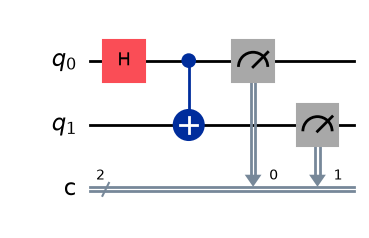

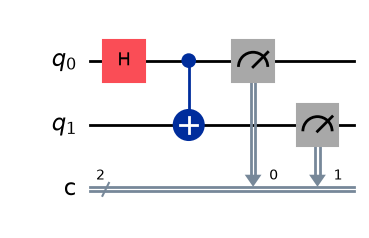

In [24]:
qreg_q = QuantumRegister(2, 'q')
creg_c = ClassicalRegister(2, 'c')
circuit = QuantumCircuit(qreg_q, creg_c)

circuit.h(qreg_q[0])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.measure(qreg_q, creg_c)

circuit.draw('mpl')

*The Qiskit diagram prepares and measures a Bell pair with $q_0$ drawn on top, a Hadamard on $q_0$, and CNOT from $q_0$ to $q_1$.*


### Qubit and bit-order conventions

Wire placement, tensor-product significance, and displayed bit strings are separate conventions. Qiskit diagrams normally draw $q_0$ at the top, while integer and ket labels treat bit 0 as the least significant bit. A displayed classical key places the most significant bit on the left. With $q_i\to c_i$, the key `10` therefore means $c_1=1,c_0=0$.

SymPy's gate indices and printed basis vectors follow its own convention. Check a small basis-state example whenever translating a circuit; do not infer semantics only from top-to-bottom wire placement.

Official reference: IBM Quantum, [Bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).


## Key takeaways

- The Bloch vector is directly related to the expectation values of $X$, $Y$, and $Z$.
- Pauli, Hadamard, phase, and rotation gates have both algebraic and geometric interpretations.
- CNOT, CZ, and related interactions can entangle suitable inputs; local gates alone cannot create bipartite entanglement.
- Logical circuits must be compiled into native instructions that respect hardware connectivity, timing, and calibration.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. IBM Quantum, [Plot quantum states](https://quantum.cloud.ibm.com/docs/en/guides/plot-quantum-states).
2. IBM Quantum, [Bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).
3. IBM Quantum, [UGate API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.UGate).
4. SymPy documentation, [Quantum gates](https://docs.sympy.org/latest/modules/physics/quantum/gate.html).
5. QuTiP documentation, [Bloch-sphere guide](https://qutip.readthedocs.io/en/stable/guide/guide-bloch.html).
6. A. Barenco et al., ["Elementary gates for quantum computation"](https://doi.org/10.1103/PhysRevA.52.3457), *Physical Review A* 52, 3457-3467 (1995).
7. M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information* (Cambridge University Press, 2010), Sections 1.2 and 4.2.
